# Edits Before the Vote: analysis notebook

**Question.** Do Wikipedia pages for Colorado's 2026 candidates get edited more in the last seven weeks before Election Day than in the summer baseline? Is the increase bigger in competitive races than in safe ones, and how much of the editing is by registered versus unregistered editors?

**What this notebook does**

1. Loads the cleaned tables made by `src/clean.py`
2. Edits per page per day by period (baseline / campaign / post-election)
3. Campaign-to-baseline ratio: competitive vs. safe, incumbents vs. challengers
4. Weekly timeline with key dates
5. Editor types and reverts by period
6. Page views vs. edits
7. Saves the summary tables to `results/` and the figures to `figures/`

Run it from the repo root after `python src/clean.py 2022` and `python src/clean.py 2026`. It reads the full tables in `data/clean/` (not in the repo, see the README). If they aren't there it falls back to the small samples in `data/sample/`, which is enough to check that the code runs but **not** enough for real results.

Everything printed here is a count, a rate or a share. No usernames, revision IDs or timestamps are shown.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

CLEAN_DIR = os.path.join("data", "clean")
SAMPLE_DIR = os.path.join("data", "sample")
FIG_DIR = "figures"
RESULTS_DIR = "results"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

CYCLES = [2022, 2026]
ELECTION = {2022: pd.Timestamp("2022-11-08"), 2026: pd.Timestamp("2026-11-03")}
CAMPAIGN_START = {2022: pd.Timestamp("2022-09-20"), 2026: pd.Timestamp("2026-09-15")}
PERIODS = ["baseline", "campaign", "post"]

## 1. Load the data

In [2]:
USING_FULL = all(
    os.path.exists(os.path.join(CLEAN_DIR, f"{name}_{cycle}.csv"))
    for name in ("edits", "page_days", "pages") for cycle in CYCLES
)


def load(name):
    frames = []
    for cycle in CYCLES:
        if USING_FULL:
            path = os.path.join(CLEAN_DIR, f"{name}_{cycle}.csv")
        elif name == "pages":
            path = os.path.join(SAMPLE_DIR, f"pages_{cycle}.csv")
        else:
            path = os.path.join(SAMPLE_DIR, f"{name}_{cycle}_sample.csv")
        frames.append(pd.read_csv(path))
    return pd.concat(frames, ignore_index=True)


pages = load("pages")
edits = load("edits")
page_days = load("page_days")

edits["date"] = pd.to_datetime(edits["date"])
page_days["date"] = pd.to_datetime(page_days["date"])

# Add each page's race information to the other two tables
info = pages[["cycle", "title", "candidate", "race", "incumbent", "competitive"]].copy()
info["race_type"] = info["competitive"].map({True: "competitive", False: "safe"})
info["role"] = info["incumbent"].map({"Y": "incumbent", "N": "challenger"})
page_days = page_days.merge(info, on=["cycle", "title"], how="left", validate="many_to_one")
edits = edits.merge(info, on=["cycle", "title"], how="left", validate="many_to_one")

print("Data source:", "FULL cleaned tables (data/clean/)" if USING_FULL
      else "SAMPLE ONLY (data/sample/) -- the numbers below are NOT real results")
for cycle in CYCLES:
    pdc = page_days[page_days["cycle"] == cycle]
    print(f"{cycle}: {(pages['cycle'] == cycle).sum()} pages, "
          f"{(edits['cycle'] == cycle).sum()} edits, {len(pdc)} page-days, "
          f"{pdc['date'].min().date()} to {pdc['date'].max().date()}")

Data source: FULL cleaned tables (data/clean/)
2022: 14 pages, 686 edits, 1876 page-days, 2022-07-12 to 2022-11-22
2026: 15 pages, 335 edits, 1725 page-days, 2026-07-14 to 2026-11-05


## 2. Edits per page per day, by period

The three periods have different lengths (the 2022 baseline is 70 days, the 2026 baseline is 63, the campaign is 50), and two 2022 pages weren't articles for the whole window. So I never compare raw counts. The measure is

> **edits per page per day** = edits on days the page was a live article ÷ number of live page-days

where a *page-day* is one page on one day (`article_live` in `page_days`). The **ratio** is the campaign rate divided by the baseline rate: 1.0 means no change, 2.0 means editing doubled.

In [3]:
live = page_days[page_days["article_live"]].copy()


def rate_table(df, by):
    """Pooled edits per page per day for each group in `by`, one column per period."""
    g = df.groupby(by + ["period"]).agg(page_days=("edits", "size"), edits=("edits", "sum"))
    g["rate"] = g["edits"] / g["page_days"]
    wide = g.unstack("period")
    out = pd.DataFrame(index=wide.index)
    for p in PERIODS:
        if ("rate", p) in wide.columns:
            out[f"{p}_page_days"] = wide[("page_days", p)]
            out[f"{p}_edits"] = wide[("edits", p)]
            out[f"{p}_rate"] = wide[("rate", p)].round(3)
    out["ratio_campaign_to_baseline"] = (wide[("rate", "campaign")] / wide[("rate", "baseline")]).round(2)
    return out


overall = rate_table(live, ["cycle"])
overall.to_csv(os.path.join(RESULTS_DIR, "rates_overall.csv"))
overall

,baseline_page_days,baseline_edits,baseline_rate,campaign_page_days,campaign_edits,campaign_rate,post_page_days,post_edits,post_rate,ratio_campaign_to_baseline
cycle,,,,,,,,,,
2022,895,209,0.234,690,212,0.307,196,264,1.347,1.32
2026,945,129,0.137,750,155,0.207,30,51,1.700,1.51


**How to read it.** `baseline_rate` and `campaign_rate` are edits per page per day. My proposal expected the ratio to be at least 2. The post-election rate is shown for context; for 2026 it only covers the days collected so far (see the date range printed in section 1).

## 3. Competitive vs. safe, incumbents vs. challengers

"Competitive" is a Cook rating of Likely or closer (set in `src/config.py`). Two ways of comparing the groups:

- **Pooled:** add up all the group's edits and all its live page-days, then divide. Busy pages count for more.
- **Median of per-page ratios** (the main number in my proposal): work out the ratio for each page, then take the group's median. Every page counts the same, but a page with no baseline edits has no ratio and drops out.

In [4]:
by_race_type = rate_table(live, ["cycle", "race_type"])
by_role = rate_table(live, ["cycle", "role"])
by_race_type.to_csv(os.path.join(RESULTS_DIR, "rates_by_race_type.csv"))
by_role.to_csv(os.path.join(RESULTS_DIR, "rates_by_role.csv"))
display(by_race_type)
display(by_role)

baseline_page_days  baseline_edits  baseline_rate  campaign_page_days  campaign_edits  campaign_rate  post_page_days  \
cycle race_type                                                                                                                           
2022  competitive                 280              42          0.150                 240              56          0.233              70   
      safe                        615             167          0.272                 450             156          0.347             126   
2026  competitive                 252               9          0.036                 200              50          0.250               8   
      safe                        693             120          0.173                 550             105          0.191              22   

                   post_edits  post_rate  ratio_campaign_to_baseline  
cycle race_type                                                       
2022  competitive          60      0.857                        1.56  
      safe                204      1.619                        1.28  
2026  competitive          16      2.000                        7.00  
      safe                 35      1.591                        1.10

baseline_page_days  baseline_edits  baseline_rate  campaign_page_days  campaign_edits  campaign_rate  post_page_days  \
cycle role                                                                                                                               
2022  challenger                 335              55          0.164                 290              82          0.283              84   
      incumbent                  560             154          0.275                 400             130          0.325             112   
2026  challenger                 441             100          0.227                 350              88          0.251              14   
      incumbent                  504              29          0.058                 400              67          0.168              16   

                  post_edits  post_rate  ratio_campaign_to_baseline  
cycle role                                                           
2022  challenger         159      1.893                        1.72  
      incumbent          105      0.938                        1.18  
2026  challenger          39      2.786                        1.11  
      incumbent           12      0.750                        2.91

In [5]:
per_page = rate_table(live, ["cycle", "title", "race", "race_type", "role"]).reset_index()
per_page = per_page[["cycle", "title", "race", "race_type", "role",
                     "baseline_page_days", "baseline_edits", "baseline_rate",
                     "campaign_page_days", "campaign_edits", "campaign_rate",
                     "ratio_campaign_to_baseline"]]
# A page with zero baseline edits (or no live baseline days) has no ratio
per_page.loc[~(per_page["baseline_edits"] > 0), "ratio_campaign_to_baseline"] = float("nan")
per_page.to_csv(os.path.join(RESULTS_DIR, "rates_per_page.csv"), index=False)
per_page.sort_values(["cycle", "race_type", "title"]).reset_index(drop=True)

,cycle,title,race,race_type,role,baseline_page_days,baseline_edits,baseline_rate,campaign_page_days,campaign_edits,campaign_rate,ratio_campaign_to_baseline
0,2022,Barbara_Kirkmeyer,CO-8,competitive,challenger,70.0,3.0,0.043,50.0,4.0,0.08,1.87
1,2022,Brittany_Pettersen,CO-7,competitive,challenger,70.0,7.0,0.100,50.0,0.0,0.00,0.00
2,2022,Joe_O'Dea,Senate,competitive,challenger,NaN,NaN,NaN,40.0,40.0,1.00,NaN
3,2022,Michael_Bennet,Senate,competitive,incumbent,70.0,24.0,0.343,50.0,5.0,0.10,0.29
4,2022,Yadira_Caraveo,CO-8,competitive,challenger,70.0,8.0,0.114,50.0,7.0,0.14,1.23
5,2022,Adam_Frisch,CO-3,safe,challenger,55.0,31.0,0.564,50.0,12.0,0.24,0.43
6,2022,Diana_DeGette,CO-1,safe,incumbent,70.0,1.0,0.014,50.0,0.0,0.00,0.00
7,2022,Doug_Lamborn,CO-5,safe,incumbent,70.0,4.0,0.057,50.0,4.0,0.08,1.40
8,2022,Heidi_Ganahl,Governor,safe,challenger,70.0,6.0,0.086,50.0,19.0,0.38,4.43
9,2022,Jared_Polis,Governor,safe,incumbent,70.0,7.0,0.100,50.0,24.0,0.48,4.80


In [6]:
def median_table(col):
    g = per_page.groupby(["cycle", col])["ratio_campaign_to_baseline"]
    return pd.DataFrame({
        "pages": g.size(),
        "pages_with_a_ratio": g.count(),
        "median_ratio": g.median().round(2),
        "lowest": g.min().round(2),
        "highest": g.max().round(2),
    })


medians = pd.concat({"race_type": median_table("race_type"), "role": median_table("role")},
                    names=["comparison", "cycle", "group"]).swaplevel(0, 1).sort_index()
medians.to_csv(os.path.join(RESULTS_DIR, "median_ratios.csv"))
medians

pages  pages_with_a_ratio  median_ratio  lowest  highest
cycle comparison group                                                                
2022  race_type  competitive      5                   4          0.76    0.00     1.87
                 safe             9                   9          0.70    0.00     4.80
      role       challenger       6                   5          1.23    0.00     4.43
                 incumbent        8                   8          0.54    0.00     4.80
2026  race_type  competitive      4                   3          4.20    0.00    11.97
                 safe            11                  11          1.05    0.00     5.04
      role       challenger       7                   7          1.05    0.52     4.20
                 incumbent        8                   7          1.97    0.00    11.97

**Caution.** There are only 14 or 15 pages per cycle and just a handful in the competitive group, and several pages have fewer than ten edits in a period. One busy page can move a group's pooled rate a lot, and one extra edit can move a small page's ratio a lot. These are descriptions of what happened on these pages, not estimates for candidates in general.

### Figure 1

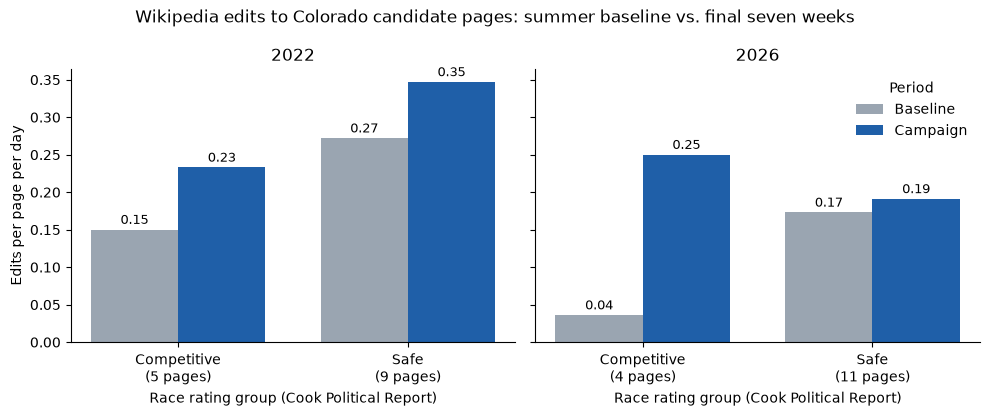

saved figures\edit_rate_by_period.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
colors = {"baseline": "#9aa5b1", "campaign": "#1f5fa8"}
for ax, cycle in zip(axes, CYCLES):
    sub = by_race_type.loc[cycle].reindex(["competitive", "safe"])
    x = range(len(sub))
    width = 0.38
    for i, p in enumerate(["baseline", "campaign"]):
        xs = [v + (i - 0.5) * width for v in x]
        bars = ax.bar(xs, sub[f"{p}_rate"], width, label=p.capitalize(), color=colors[p])
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
    labels = [f"{name.capitalize()}\n({(info[(info['cycle'] == cycle)]['race_type'] == name).sum()} pages)"
              for name in sub.index]
    ax.set_xticks(list(x), labels)
    ax.set_title(str(cycle))
    ax.set_xlabel("Race rating group (Cook Political Report)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Edits per page per day")
axes[1].legend(title="Period", frameon=False)
fig.suptitle("Wikipedia edits to Colorado candidate pages: summer baseline vs. final seven weeks")
fig.tight_layout()
fig_path = os.path.join(FIG_DIR, "edit_rate_by_period.png")
fig.savefig(fig_path, dpi=200)
plt.show()
print("saved", fig_path)

**Figure 1.** Edits per page per day in the summer baseline and in the final seven weeks before Election Day, for candidates in competitive races (Cook rating of Likely or closer) and safe races, in 2022 and 2026.

## 4. Weekly timeline

Weeks are counted back from Election Day, so week 0 is the seven days ending on Election Day and every week before it is a full seven days. The first and last weeks of the window can be shorter, which is why the measure is again edits per page per day.

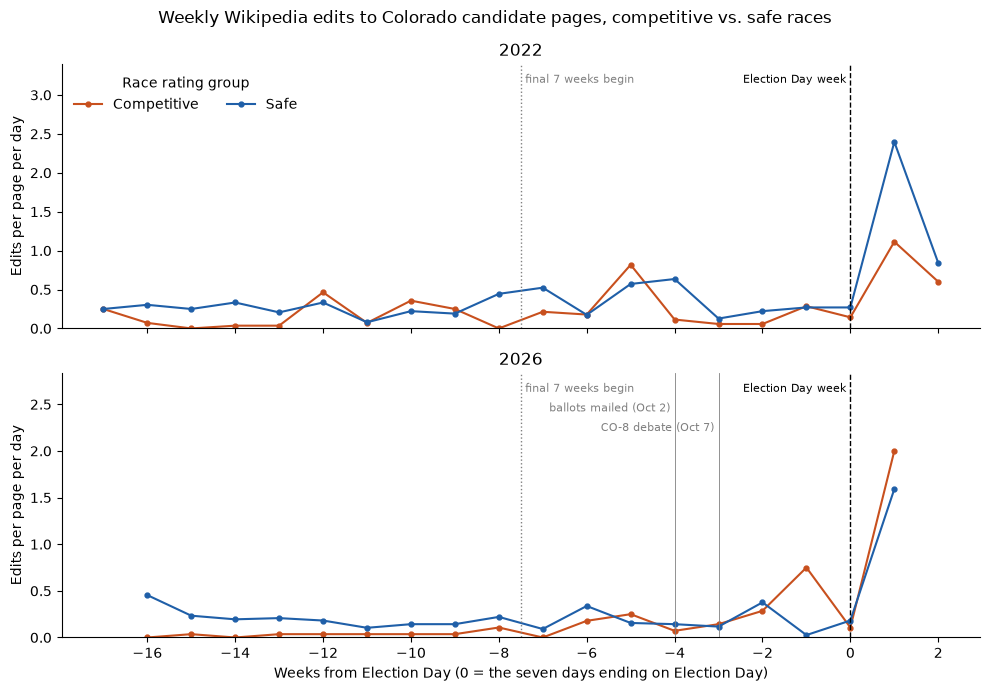

saved figures\weekly_timeline.png


In [8]:
weekly_frames = []
for cycle in CYCLES:
    sub = live[live["cycle"] == cycle].copy()
    days_from_election = (sub["date"] - ELECTION[cycle]).dt.days
    sub["week"] = -((-days_from_election) // 7)      # days -6..0 -> week 0, days 1..7 -> week 1
    w = sub.groupby(["cycle", "race_type", "week"]).agg(page_days=("edits", "size"), edits=("edits", "sum"))
    w["rate"] = w["edits"] / w["page_days"]
    weekly_frames.append(w.reset_index())
weekly = pd.concat(weekly_frames, ignore_index=True)
weekly.to_csv(os.path.join(RESULTS_DIR, "weekly_rates.csv"), index=False)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
line_colors = {"competitive": "#c8501e", "safe": "#1f5fa8"}
for ax, cycle in zip(axes, CYCLES):
    for name in ["competitive", "safe"]:
        s = weekly[(weekly["cycle"] == cycle) & (weekly["race_type"] == name)]
        ax.plot(s["week"], s["rate"], marker="o", markersize=3.5, label=name.capitalize(), color=line_colors[name])
    start_week = -(((ELECTION[cycle] - CAMPAIGN_START[cycle]).days) // 7)
    top = ax.get_ylim()[1]
    ax.set_ylim(0, top * 1.35)          # headroom for the labels
    ax.axvline(start_week - 0.5, color="gray", linestyle=":", linewidth=1)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.text(start_week - 0.4, top * 1.30, "final 7 weeks begin", fontsize=8, color="gray", va="top")
    ax.text(-0.1, top * 1.30, "Election Day week", fontsize=8, va="top", ha="right")
    if cycle == 2026:
        for label, day, height in [("ballots mailed (Oct 2)", "2026-10-02", 1.20),
                                   ("CO-8 debate (Oct 7)", "2026-10-07", 1.10)]:
            wk = -((ELECTION[cycle] - pd.Timestamp(day)).days // 7)
            ax.axvline(wk, color="gray", linestyle="-", linewidth=0.6)
            ax.text(wk - 0.1, top * height, label, fontsize=8, color="gray", va="top", ha="right")
    ax.xaxis.set_major_locator(plt.MultipleLocator(2))
    ax.set_title(str(cycle))
    ax.set_ylabel("Edits per page per day")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(title="Race rating group", frameon=False, loc="upper left", ncols=2)
axes[1].set_xlabel("Weeks from Election Day (0 = the seven days ending on Election Day)")
fig.suptitle("Weekly Wikipedia edits to Colorado candidate pages, competitive vs. safe races")
fig.tight_layout()
fig_path = os.path.join(FIG_DIR, "weekly_timeline.png")
fig.savefig(fig_path, dpi=200)
plt.show()
print("saved", fig_path)

**Figure 2.** Edits per page per day in each week before and after Election Day, for candidate pages in competitive and safe races, in 2022 and 2026.

## 5. Who is editing, and how much gets reverted

"Unregistered" means IP addresses in 2022 and temporary accounts in 2026 (English Wikipedia switched on November 4, 2025). Unregistered editors can't edit a protected page, so the second table repeats the share using only edits made on days the page was *not* edit-protected.

In [9]:
def share_table(df):
    g = df.groupby(["cycle", "period"]).agg(
        edits=("editor_type", "size"),
        registered=("editor_type", lambda s: (s == "registered").sum()),
        unregistered=("unregistered", "sum"),
        bot=("editor_type", lambda s: (s == "bot").sum()),
        reverted=("was_reverted", "sum"),
    )
    g["pct_unregistered"] = (100 * g["unregistered"] / g["edits"]).round(1)
    g["pct_reverted"] = (100 * g["reverted"] / g["edits"]).round(1)
    return g.reindex(PERIODS, level="period")


editor_shares = share_table(edits)
editor_shares.to_csv(os.path.join(RESULTS_DIR, "editor_shares.csv"))
display(editor_shares)

# Same thing, leaving out edits made while the page was edit-protected
prot = page_days[["cycle", "title", "date", "edit_protection"]]
edits_p = edits.merge(prot, on=["cycle", "title", "date"], how="left")
unprotected = edits_p[edits_p["edit_protection"].fillna("none") == "none"]
editor_shares_unprotected = share_table(unprotected)
editor_shares_unprotected.to_csv(os.path.join(RESULTS_DIR, "editor_shares_unprotected_days.csv"))
print("Edits on days when the page was not edit-protected:")
display(editor_shares_unprotected)

reverted_by_type = edits.groupby(["cycle", "unregistered"]).agg(
    edits=("was_reverted", "size"), reverted=("was_reverted", "sum"))
reverted_by_type["pct_reverted"] = (100 * reverted_by_type["reverted"] / reverted_by_type["edits"]).round(1)
reverted_by_type.to_csv(os.path.join(RESULTS_DIR, "reverted_by_editor_type.csv"))
print("Share reverted, registered/bot (False) vs. unregistered (True):")
display(reverted_by_type)

edits  registered  unregistered  bot  reverted  pct_unregistered  pct_reverted
cycle period                                                                                  
2022  baseline    209         178            24    7        26              11.5          12.4
      campaign    213         161            39   13        53              18.3          24.9
      post        264         220            41    3        43              15.5          16.3
2026  baseline    129         106            22    1        15              17.1          11.6
      campaign    155         130            20    5         7              12.9           4.5
      post         51          43             8    0         5              15.7           9.8

Edits on days when the page was not edit-protected:


edits  registered  unregistered  bot  reverted  pct_unregistered  pct_reverted
cycle period                                                                                  
2022  baseline    155         125            24    6        17              15.5          11.0
      campaign    160         121            30    9        26              18.8          16.2
      post        198         155            41    2        30              20.7          15.2
2026  baseline    105          83            22    0        14              21.0          13.3
      campaign    128         105            19    4         6              14.8           4.7
      post         36          28             8    0         4              22.2          11.1

Share reverted, registered/bot (False) vs. unregistered (True):


edits  reverted  pct_reverted
cycle unregistered                               
2022  False           582        81          13.9
      True            104        41          39.4
2026  False           285         9           3.2
      True             50        18          36.0

## 6. Does editing just follow page views?

If editing only tracked attention, edits and views would rise by the same factor and edits per 10,000 views would stay flat between baseline and campaign.

In [10]:
v = live.groupby(["cycle", "race_type", "period"]).agg(
    page_days=("views", "size"), views=("views", "sum"), edits=("edits", "sum"))
v["views_per_page_day"] = (v["views"] / v["page_days"]).round(0)
v["edits_per_10k_views"] = (10000 * v["edits"] / v["views"]).round(2)
v = v.reindex(PERIODS, level="period")
v.to_csv(os.path.join(RESULTS_DIR, "views_vs_edits.csv"))
display(v)

growth = pd.DataFrame({
    "views_ratio": (v.xs("campaign", level="period")["views"] / v.xs("campaign", level="period")["page_days"])
                   / (v.xs("baseline", level="period")["views"] / v.xs("baseline", level="period")["page_days"]),
    "edits_ratio": (v.xs("campaign", level="period")["edits"] / v.xs("campaign", level="period")["page_days"])
                   / (v.xs("baseline", level="period")["edits"] / v.xs("baseline", level="period")["page_days"]),
}).round(2)
print("Campaign divided by baseline, per page per day:")
display(growth)

# Day-by-day link: for each page, the Spearman (rank) correlation between daily views and
# daily edits. Pages with the same number of edits every day have no correlation.
corr = (live.groupby(["cycle", "title"])[["views", "edits"]]
        .apply(lambda d: d["views"].rank().corr(d["edits"].rank()) if d["edits"].nunique() > 1 else float("nan"))
        .rename("spearman_views_edits").reset_index())
print("Median per-page Spearman correlation between daily views and daily edits:")
print(corr.groupby("cycle")["spearman_views_edits"].median().round(2).to_string())

page_days      views  edits  views_per_page_day  edits_per_10k_views
cycle race_type   period                                                                        
2022  competitive baseline        280    57658.0     42               206.0                 7.28
                  campaign        240    84645.0     56               353.0                 6.62
                  post             70    72520.0     60              1036.0                 8.27
      safe        baseline        615   479106.0    167               779.0                 3.49
                  campaign        450   287032.0    156               638.0                 5.43
                  post            126  1179725.0    204              9363.0                 1.73
2026  competitive baseline        252    58928.0      9               234.0                 1.53
                  campaign        200   117229.0     50               586.0                 4.27
                  post              8    51357.0     16              6420.0                 3.12
      safe        baseline        693   460244.0    120               664.0                 2.61
                  campaign        550   510276.0    105               928.0                 2.06
                  post             22   322984.0     35             14681.0                 1.08

Campaign divided by baseline, per page per day:


views_ratio  edits_ratio
cycle race_type                            
2022  competitive         1.71         1.56
      safe                0.82         1.28
2026  competitive         2.51         7.00
      safe                1.40         1.10

Median per-page Spearman correlation between daily views and daily edits:
cycle
2022    0.17
2026    0.12


## 7. Numbers for the README

In [11]:
print("Data source:", "full cleaned tables" if USING_FULL else "SAMPLE ONLY -- not real results")
for cycle in CYCLES:
    pdc = page_days[page_days["cycle"] == cycle]
    o = overall.loc[cycle]
    print(f"\n{cycle} (data through {pdc['date'].max().date()})")
    print(f"  all pages: baseline {o['baseline_rate']:.3f} -> campaign {o['campaign_rate']:.3f} "
          f"edits per page per day, ratio {o['ratio_campaign_to_baseline']:.2f}")
    if "post_rate" in o:
        print(f"  post-election so far: {o['post_rate']:.3f} edits per page per day "
              f"({int(o['post_edits'])} edits on {int(o['post_page_days'])} page-days)")
    for name in ["competitive", "safe"]:
        r = by_race_type.loc[(cycle, name)]
        m = medians.loc[(cycle, "race_type", name)]
        print(f"  {name}: baseline {r['baseline_rate']:.3f} -> campaign {r['campaign_rate']:.3f}, "
              f"pooled ratio {r['ratio_campaign_to_baseline']:.2f}, median per-page ratio {m['median_ratio']:.2f} "
              f"({int(m['pages_with_a_ratio'])} of {int(m['pages'])} pages)")
    for name in ["incumbent", "challenger"]:
        r = by_role.loc[(cycle, name)]
        m = medians.loc[(cycle, "role", name)]
        print(f"  {name}: pooled ratio {r['ratio_campaign_to_baseline']:.2f}, "
              f"median per-page ratio {m['median_ratio']:.2f}")
    for p in PERIODS:
        if (cycle, p) in editor_shares.index and editor_shares.loc[(cycle, p), "edits"] > 0:
            e = editor_shares.loc[(cycle, p)]
            print(f"  {p}: {e['pct_unregistered']:.1f}% of {int(e['edits'])} edits unregistered, "
                  f"{e['pct_reverted']:.1f}% reverted")
    for name in ["competitive", "safe"]:
        g = growth.loc[(cycle, name)]
        print(f"  {name}: views x{g['views_ratio']:.2f}, edits x{g['edits_ratio']:.2f} (campaign vs. baseline)")

Data source: full cleaned tables

2022 (data through 2022-11-22)
  all pages: baseline 0.234 -> campaign 0.307 edits per page per day, ratio 1.32
  post-election so far: 1.347 edits per page per day (264 edits on 196 page-days)
  competitive: baseline 0.150 -> campaign 0.233, pooled ratio 1.56, median per-page ratio 0.76 (4 of 5 pages)
  safe: baseline 0.272 -> campaign 0.347, pooled ratio 1.28, median per-page ratio 0.70 (9 of 9 pages)
  incumbent: pooled ratio 1.18, median per-page ratio 0.54
  challenger: pooled ratio 1.72, median per-page ratio 1.23
  baseline: 11.5% of 209 edits unregistered, 12.4% reverted
  campaign: 18.3% of 213 edits unregistered, 24.9% reverted
  post: 15.5% of 264 edits unregistered, 16.3% reverted
  competitive: views x1.71, edits x1.56 (campaign vs. baseline)
  safe: views x0.82, edits x1.28 (campaign vs. baseline)

2026 (data through 2026-11-05)
  all pages: baseline 0.137 -> campaign 0.207 edits per page per day, ratio 1.51
  post-election so far: 1.700 